<h1>Semi-Supervised Learning & Label Spreading</h1>

In semi-supervised learning only **some** of the samples have labels. Semi-supervised
algorithms sit between supervised and unsupervised learning: they use the labelled
samples *and* the shape of the unlabelled data to estimate the missing labels.

**Label Spreading** builds a graph connecting similar data points, then lets the known
labels spread across the graph to their unlabelled neighbours — like drops of dye
spreading through water. (Technically: it minimises a loss function with regularisation,
using edge weights from the normalised graph Laplacian matrix.)

In this notebook we use the classic Iris dataset: 150 flowers, 4 measurements each,
3 species — then hide most of the labels and see how well they can be recovered.

[SciKit Label Spreading](https://scikit-learn.org/stable/modules/generated/sklearn.semi_supervised.LabelSpreading.html)

<h1>Step 1: Import libraries</h1>

In [1]:
# import the libraries we need:
# numpy               -> random numbers and array handling
# datasets            -> sklearn's built-in datasets (includes Iris)
# LabelSpreading      -> the semi-supervised algorithm
# LogisticRegression  -> a supervised model to compare against
# accuracy_score, confusion_matrix -> for honest evaluation
import numpy as np
from sklearn import datasets
from sklearn.semi_supervised import LabelSpreading
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from IPython.display import display, Markdown, HTML
from notebook_display import display_estimator
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import pandas as pd
import seaborn as sns
from numpy.typing import ArrayLike
from sklearn.utils import Bunch

The plotting functions below help visualise the data and the models' predictions:

- `plot_iris`: shows label proportions on the left and petal measurements on the right.
- `plot_prediction_results`: shows which hidden-label samples each model classified correctly or incorrectly.
- `plot_confusion_matrices`: compares true and predicted species for the hidden-label samples.

In [2]:
def plot_iris(
    iris: Bunch,
    labels: ArrayLike | None = None,
    title: str = "Iris Dataset",
    palette_style: str = "deep",
    small_slice_threshold: float = 0.05,
) -> None:
    """Plot label proportions and petal measurements for the Iris dataset.

    Args:
        iris: Dataset returned by sklearn.datasets.load_iris().
        labels: One label per sample. Use species codes 0, 1, 2,
            or -1 for unlabelled samples. Defaults to iris.target.
        title: Overall title for the figure.
        palette_style: Colour palette for the plot. Use "deep" for vibrant colours
            and "pastel" for muted colours.
        small_slice_threshold: Proportion below which pie slices receive arrows.
            Defaults to 0.05 (5%).

    Unlabelled samples are shown in grey. Species colours remain
    consistent across calls.
    """
    labels = np.asarray(iris.target if labels is None else labels)

    if labels.shape != (len(iris.data),):
        raise ValueError("Provide exactly one label per flower.")

    valid_labels = [-1, *range(len(iris.target_names))]
    if not np.isin(labels, valid_labels).all():
        raise ValueError(f"Labels must be one of {valid_labels}.")

    label_names = {
        i: str(name) for i, name in enumerate(iris.target_names)
    }
    label_names[-1] = "Unlabelled"

    iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
    iris_df["Label"] = [label_names[int(label)] for label in labels]

    # Keep species colours consistent, even when some labels are absent.
    palette = dict(zip(
        map(str, iris.target_names),
        sns.color_palette(palette_style, n_colors=len(iris.target_names)),
    ))
    palette["Unlabelled"] = "#b0b0b0"

    order = [
        name for name in palette
        if name in iris_df["Label"].values
    ]
    counts = iris_df["Label"].value_counts().reindex(order)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(title)

    '''axes[0].pie(
        counts,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=[palette[name] for name in counts.index],
    )
    axes[0].set_title("Label Proportions")'''
    proportions = counts / counts.sum()
    small_slices = proportions < small_slice_threshold

    wedges, _ = axes[0].pie(
        counts,
        labels=[
            "" if small else name
            for name, small in zip(counts.index, small_slices)
        ],
        startangle=90,
        colors=[palette[name] for name in counts.index],
        labeldistance=1.1,
    )

    sides = {-1: [], 1: []}

    for wedge, name, proportion, small in zip(
        wedges, counts.index, proportions, small_slices
    ):
        angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
        x, y = np.cos(angle), np.sin(angle)

        if small:
            side = 1 if x >= 0 else -1
            sides[side].append((y, x, name, proportion))
        else:
            # Larger slices keep their percentage inside the pie.
            axes[0].text(
                0.65 * x,
                0.65 * y,
                f"{proportion:.1%}",
                ha="center",
                va="center",
            )

    # Only small slices receive external labels and arrows.
    for side, entries in sides.items():
        entries.sort(key=lambda entry: entry[0])

        if not entries:
            continue

        positions = (
            np.linspace(-1.2, 1.2, len(entries))
            if len(entries) > 1
            else [entries[0][0] * 1.2]
        )

        for (y, x, name, proportion), label_y in zip(entries, positions):
            axes[0].annotate(
                f"{name}: {proportion:.1%}",
                xy=(x, y),
                xytext=(side * 1.7, label_y),
                ha="left" if side == 1 else "right",
                va="center",
                fontsize=9,
                arrowprops={
                    "arrowstyle": "->",
                    "color": palette[name],
                    "connectionstyle": "arc3",
                },
            )

    axes[0].set_xlim(-2.6, 2.6)
    axes[0].set_ylim(-1.5, 1.5)
    axes[0].set_title("Label Proportions")

    sns.scatterplot(
        data=iris_df,
        x="petal length (cm)",
        y="petal width (cm)",
        hue="Label",
        style="Label",
        hue_order=order,
        style_order=order,
        palette=palette,
        s=65,
        ax=axes[1],
    )
    axes[1].set_title("Petal Measurements by Label")
    axes[1].set_xlabel("Petal Length (cm)")
    axes[1].set_ylabel("Petal Width (cm)")

    plt.tight_layout()
    plt.show()

def plot_prediction_results(
    iris: Bunch,
    hidden: ArrayLike,
    label_spreading_predictions: ArrayLike,
    logistic_regression_predictions: ArrayLike,
) -> None:
    """Compare classification results on flowers with hidden labels.

    Args:
        iris: Dataset returned by sklearn.datasets.load_iris().
        hidden: Boolean mask identifying flowers with hidden labels.
        label_spreading_predictions: Predictions for all flowers.
        logistic_regression_predictions: Predictions for hidden flowers
            only, in their original dataset order.

    Colours indicate true species. Circles indicate correct predictions;
    crosses indicate incorrect predictions.
    """
    hidden = np.asarray(hidden, dtype=bool)
    lb_predictions = np.asarray(label_spreading_predictions)
    lr_predictions = np.asarray(logistic_regression_predictions)

    if hidden.shape != iris.target.shape:
        raise ValueError("hidden must have one entry per flower.")
    if not hidden.any():
        raise ValueError("At least one flower must have a hidden label.")
    if lb_predictions.shape != iris.target.shape:
        raise ValueError("Label Spreading must predict all flowers.")
    if lr_predictions.shape != (int(hidden.sum()),):
        raise ValueError("Logistic Regression must predict hidden flowers only.")

    true_labels = iris.target[hidden]
    plot_data = pd.DataFrame(
        iris.data[hidden],
        columns=iris.feature_names,
    )
    plot_data["True species"] = iris.target_names[true_labels]

    palette = dict(zip(
        iris.target_names,
        sns.color_palette("deep", n_colors=len(iris.target_names)),
    ))

    fig, axes = plt.subplots(
        1, 2, figsize=(15, 5), sharex=True, sharey=True
    )
    fig.suptitle(
        f"Predictions on Hidden Labels — {hidden.mean():.1%} Hidden"
    )

    for ax, predictions, title in [
        (axes[0], lb_predictions[hidden], "Label Spreading"),
        (axes[1], lr_predictions, "Logistic Regression"),
    ]:
        correct = predictions == true_labels
        panel = plot_data.assign(
            Result=np.where(correct, "Correct", "Incorrect")
        )

        # Draw incorrect predictions last so they remain visible.
        panel = panel.sort_values("Result")

        sns.scatterplot(
            data=panel,
            x="petal length (cm)",
            y="petal width (cm)",
            hue="True species",
            hue_order=list(iris.target_names),
            palette=palette,
            style="Result",
            style_order=["Correct", "Incorrect"],
            markers={"Correct": "o", "Incorrect": "X"},
            s=85,
            ax=ax,
        )

        ax.set_title(
            f"{title}\n"
            f"{correct.sum()}/{len(correct)} correct ({correct.mean():.1%})"
        )
        ax.set_xlabel("Petal Length (cm)")
        ax.set_ylabel("Petal Width (cm)")

    plt.tight_layout()
    plt.show()

def plot_confusion_matrices(
    true_labels: ArrayLike,
    hidden: ArrayLike,
    label_spreading_predictions: ArrayLike,
    logistic_regression_predictions: ArrayLike,
    class_names: ArrayLike,
) -> None:
    """Compare both models on samples whose labels were hidden.

    Args:
        true_labels: True labels for the complete dataset.
        hidden: Boolean mask identifying samples with hidden labels.
        label_spreading_predictions: Predictions for the complete dataset.
        logistic_regression_predictions: Predictions for hidden samples
            only, in their original dataset order.
        class_names: Names corresponding to class codes 0, 1, 2, etc.

    Displays counts for each true/predicted class combination.
    The title reports the actual proportion of hidden labels.
    """
    true_labels = np.asarray(true_labels)
    hidden = np.asarray(hidden, dtype=bool)
    lb_predictions = np.asarray(label_spreading_predictions)
    lr_predictions = np.asarray(logistic_regression_predictions)

    if hidden.shape != true_labels.shape:
        raise ValueError("hidden must have one entry per true label.")
    if lb_predictions.shape != true_labels.shape:
        raise ValueError("Label Spreading must provide one prediction per sample.")
    if lr_predictions.shape != (int(hidden.sum()),):
        raise ValueError("Logistic Regression must predict only hidden samples.")
    if not hidden.any():
        raise ValueError("At least one sample must have a hidden label.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(
        f"Hidden Labels: {hidden.mean():.1%} "
        f"({hidden.sum()} of {hidden.size} samples)"
    )

    for ax, predictions, title in [
        (axes[0], lb_predictions[hidden], "Label Spreading"),
        (axes[1], lr_predictions, "Logistic Regression"),
    ]:
        ConfusionMatrixDisplay.from_predictions(
            true_labels[hidden],
            predictions,
            labels=range(len(class_names)),
            display_labels=class_names,
            cmap="Blues",
            colorbar=False,
            values_format="d",
            ax=ax,
        )
        ax.set_title(title)

    plt.tight_layout()
    plt.show()

<h1>Step 2: Import the dataset</h1>

The Iris dataset is included in scikit-learn, so no separate dataset download is needed.

In [3]:
# load the Iris dataset
iris = datasets.load_iris()

# quick orientation: how many flowers, how many measurements, which species
print("data shape:", iris.data.shape)          # (150 flowers, 4 measurements)
print("species:", list(iris.target_names))     # 0=setosa, 1=versicolor, 2=virginica

data shape: (150, 4)
species: ['setosa', 'versicolor', 'virginica']


The code below visualises the dataset. In particular, `plot_iris` shows the proportion of flowers in each species and their petal measurements. When labels are hidden, it also shows which flowers are unlabelled.

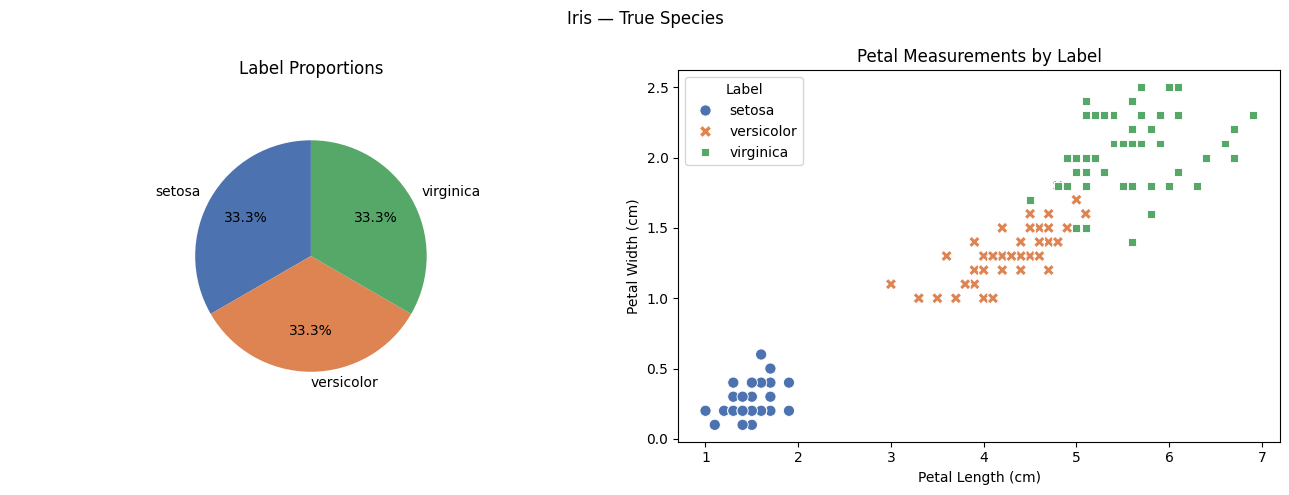

In [4]:
plot_iris(iris, title="Iris — True Species")

<h1>Step 3: Create the random number generator and the model</h1>

We create a seeded random number generator and an instance of the `LabelSpreading` model.
Reinitialising the generator with the same seed reproduces the same random sequence.
Rerunning only a cell that draws random numbers advances that sequence and can change the split.

In [5]:
# A fixed seed reproduces the sequence when this generator is reinitialised.
rand = np.random.RandomState(0)

# the Label Spreading model, with its default settings
label_spreading_model = LabelSpreading()

display(Markdown(f"**Random number generator (seed 0):** `{rand}`"))

display(Markdown("### Label Spreading Model"))
display_estimator(label_spreading_model)

**Random number generator (seed 0):** `RandomState(MT19937)`

### Label Spreading Model

LabelSpreading()

<h2>Step 3.1: Hiding the labels</h2>

Now we hide roughly 70% of the labels. scikit-learn's convention for
"this sample is unlabelled" is the value **-1** — the model treats every
-1 as a label it must work out for itself.

total flowers: 150
labels hidden: 111
labels kept:   39


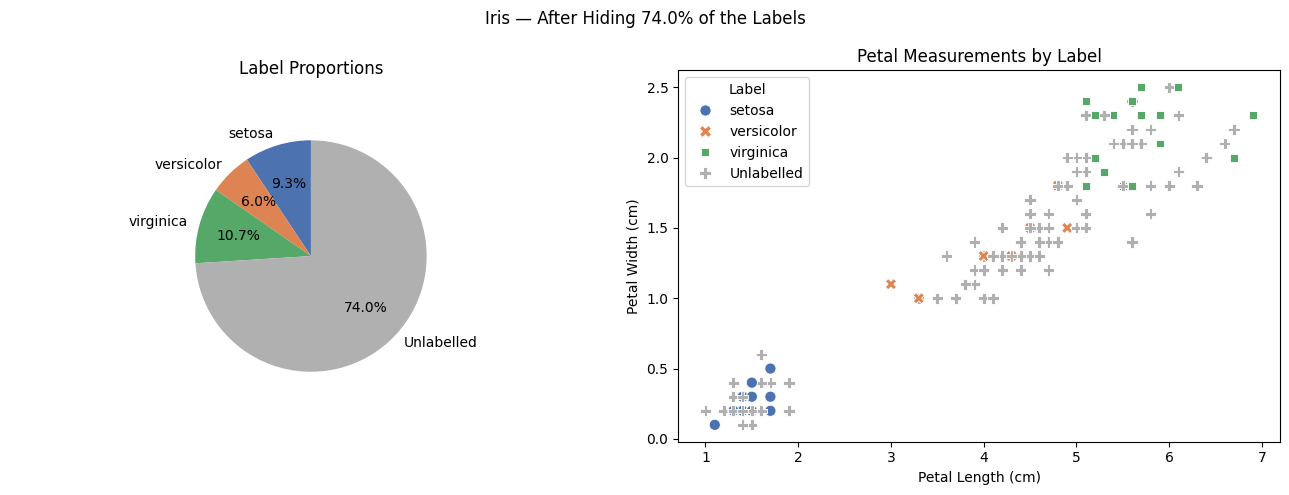

In [6]:
# draw a random number 0-1 for each flower; True (about 70% of them) = hide its label
random_unlabeled_samples = rand.rand(len(iris.target)) <= 0.7

# copy the true labels, then overwrite the hidden ones with -1
# (we keep iris.target untouched — we need the truth later for marking)
un_labelled = np.copy(iris.target)
un_labelled[random_unlabeled_samples] = -1

# how did the split land?
print("total flowers:", len(un_labelled))
print("labels hidden:", random_unlabeled_samples.sum())
print("labels kept:  ", (~random_unlabeled_samples).sum())

plot_iris(
    iris,
    labels=un_labelled,
    title=f"Iris — After Hiding {random_unlabeled_samples.mean():.1%} of the Labels",
)

<h2>Step 3.2: Inspect the labels</h2>

Every -1 below is a flower the model must label for itself. The scattered
0s, 1s and 2s are the few flowers that kept their species label.

In [7]:
# print the label array the model will be given
print(un_labelled)

label_colours = {
    i: to_hex(colour)
    for i, colour in enumerate(sns.color_palette("deep", n_colors=3))
}
label_colours[-1] = "#808080"

coloured_labels = " ".join(
    f'<span style="color: {label_colours[int(label)]}; '
    f'font-weight: bold;">{int(label):2d}</span>'
    for label in un_labelled
)

latex_labels = r"\ ".join(
    r"\textcolor[HTML]{"
    + label_colours[int(label)].lstrip("#").upper()
    + r"}{\texttt{"
    + str(int(label))
    + "}}"
    for label in un_labelled
)

display(
    {
        "text/html": (
            '<pre style="white-space: pre-wrap;">'
            f'[{coloured_labels}]'
            '</pre>'
        ),
        "text/latex": (
            r"\begin{quote}\raggedright "
            "[" + latex_labels + "]"
            r"\end{quote}"
        ),
        "text/plain": str(un_labelled),
    },
    raw=True,
)

[-1  0 -1 -1 -1 -1 -1  0  0 -1  0 -1 -1  0 -1 -1 -1  0  0  0  0  0 -1  0
 -1 -1 -1  0 -1 -1 -1  0 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1  1 -1  1 -1
  1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1  1 -1 -1
 -1 -1  1 -1 -1 -1  2  2 -1 -1 -1 -1 -1  2 -1  2 -1 -1  2 -1  2 -1  2 -1
  2 -1  2 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1  2
  2  2 -1  2  2  2]


[-1  0 -1 -1 -1 -1 -1  0  0 -1  0 -1 -1  0 -1 -1 -1  0  0  0  0  0 -1  0
 -1 -1 -1  0 -1 -1 -1  0 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1  1 -1  1 -1
  1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1  1 -1 -1
 -1 -1  1 -1 -1 -1  2  2 -1 -1 -1 -1 -1  2 -1  2 -1 -1  2 -1  2 -1  2 -1
  2 -1  2 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  2 -1 -1  2
  2  2 -1  2  2  2]

<h1>Step 4: Fit and evaluate the model</h1>

We fit Label Spreading using measurements from all 150 flowers, with retained species
labels for some flowers and `-1` for the rest. We then predict a species for every flower.

We compare predictions with the **true labels** stored in `iris.target`.
The overall accuracy includes flowers whose labels were supplied during fitting.
Accuracy on the hidden-label samples measures recovery of the withheld labels.

This is a **transductive evaluation**, not an independent test-set evaluation:
Label Spreading has already used the hidden-label samples' measurements during fitting.

In [8]:
# fit the model: it sees the measurements for all flowers,
# but only the labels that were retained
label_spreading_model.fit(iris.data, un_labelled)

# predict a species for every flower
pred_lb = label_spreading_model.predict(iris.data)

# mark against the TRUE labels
overall = accuracy_score(iris.target, pred_lb)
print(f"Accuracy on all 150 flowers: {overall:.1%}")

'''hidden_accuracy = accuracy_score(
    iris.target[random_unlabeled_samples],
    pred_lb[random_unlabeled_samples],
)
print(f"Accuracy on flowers with hidden labels: {hidden_accuracy:.1%}")'''

# Evaluate withheld labels; these flowers' features were used during fitting.
hidden = random_unlabeled_samples
hidden_acc = accuracy_score(iris.target[hidden], pred_lb[hidden])
print(f"Accuracy on the {hidden.sum()} hidden flowers: {hidden_acc:.1%}",
      f"({(iris.target[hidden] == pred_lb[hidden]).sum()} of {hidden.sum()} recovered)")

Accuracy on all 150 flowers: 94.7%
Accuracy on the 111 hidden flowers: 92.8% (103 of 111 recovered)


<h1>Step 5: Compare with supervised learning</h1>

To put the hidden-label accuracy in context, we train Logistic Regression using only
the flowers whose labels were retained. Both models then predict the same hidden-label
samples and are evaluated against their true species.

The models receive the same labelled samples, but Label Spreading also uses the
unlabelled samples' measurements during fitting. The printed counts and scores
describe the current run.

In [9]:
# train Logistic Regression on ONLY the flowers that kept their labels
# (max_iter=1000 simply gives the solver plenty of room to converge)
supervised = LogisticRegression(random_state=0, max_iter=1000)
supervised.fit(iris.data[~hidden], iris.target[~hidden])

# both models label the same hidden flowers
lr_pred = supervised.predict(iris.data[hidden])
lr_acc = accuracy_score(iris.target[hidden], lr_pred)

print(f"Label Spreading on the hidden flowers: {hidden_acc:.1%}")
print(f"Logistic Regression on the hidden flowers: {lr_acc:.1%}")

# confusion matrices (rows = actual species, columns = predicted)
print("\nLabel Spreading:")
print(confusion_matrix(iris.target[hidden], pred_lb[hidden]))
print("\nLogistic Regression:")
print(confusion_matrix(iris.target[hidden], lr_pred))

Label Spreading on the hidden flowers: 92.8%
Logistic Regression on the hidden flowers: 95.5%

Label Spreading:
[[36  0  0]
 [ 0 40  1]
 [ 0  7 27]]

Logistic Regression:
[[36  0  0]
 [ 0 39  2]
 [ 0  3 31]]


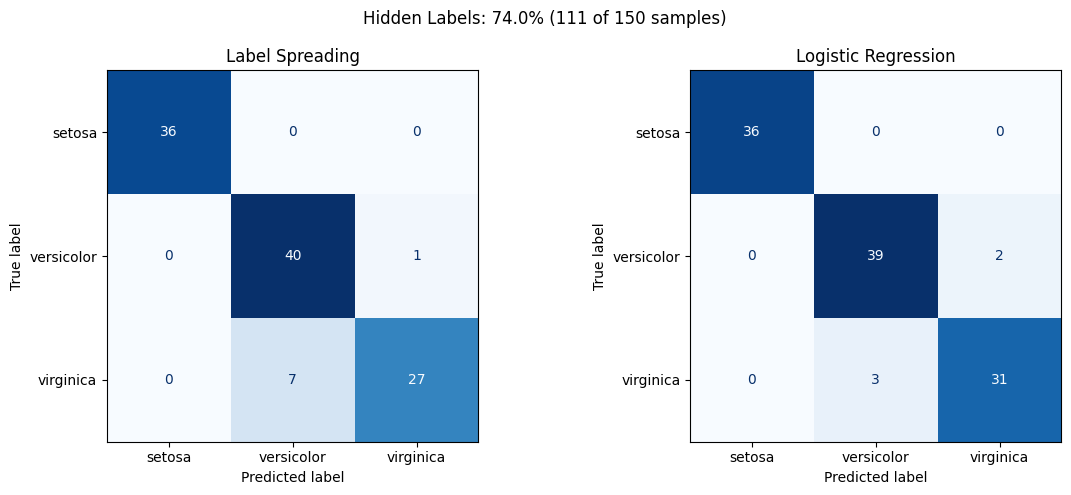

In [10]:
plot_confusion_matrices(
    true_labels=iris.target,
    hidden=hidden,
    label_spreading_predictions=pred_lb,
    logistic_regression_predictions=lr_pred,
    class_names=iris.target_names,
)

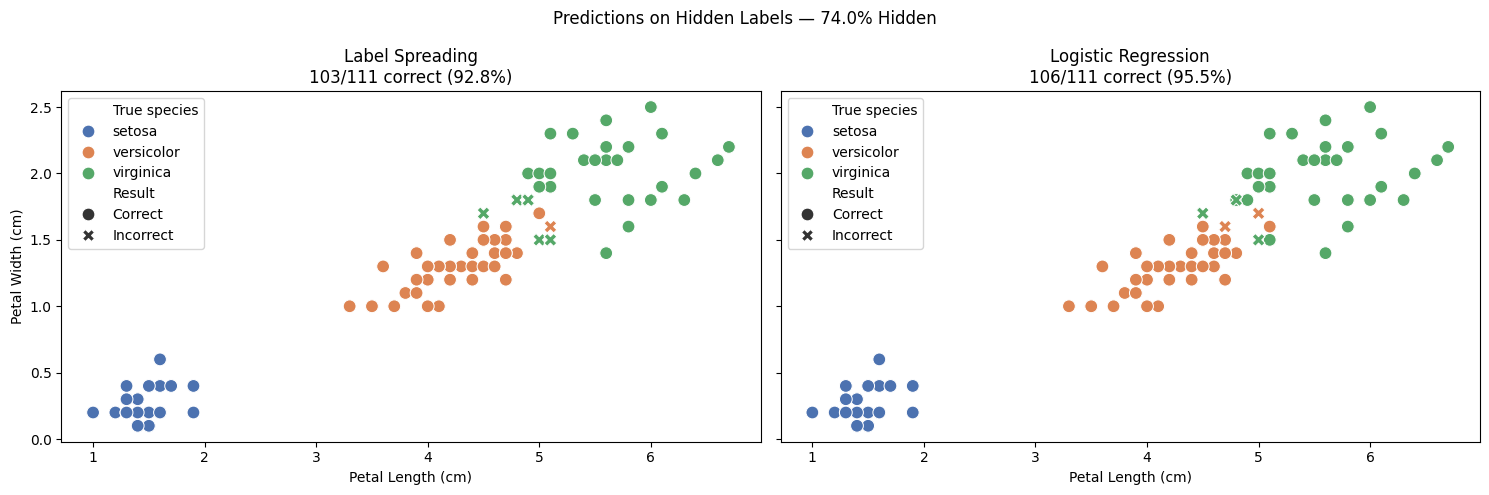

In [11]:
plot_prediction_results(
    iris=iris,
    hidden=hidden,
    label_spreading_predictions=pred_lb,
    logistic_regression_predictions=lr_pred,
)

<h1>Step 6: What happens when labels are scarcer?</h1>

Labelling data can be expensive—for example, paying a botanist to identify each flower.
We repeat the experiment with a **90% probability of hiding each label**.
This retains about 15 labels on average; the seeded run shown here retains 14.

This lets us explore whether Label Spreading benefits from the unlabelled measurements
when fewer labels are available. An improvement is possible, but not guaranteed.

In [12]:
# Same experiment, but give each label a 90% chance of being hidden.
rand2 = np.random.RandomState(0)
scarce = rand2.rand(len(iris.target)) <= 0.9

un_labelled_scarce = np.copy(iris.target)
un_labelled_scarce[scarce] = -1
print("labels kept this time:", (~scarce).sum())

# Label Spreading: learns from the few labels AND the shape of all the data
ls2 = LabelSpreading()
ls2.fit(iris.data, un_labelled_scarce)
ls_pred_scarce = ls2.predict(iris.data) # contains predictions for all flowers.
ls2_acc = accuracy_score(iris.target[scarce], ls_pred_scarce[scarce])

# Logistic Regression: can only learn from the few labelled flowers
lr2 = LogisticRegression(random_state=0, max_iter=1000)
lr2.fit(iris.data[~scarce], iris.target[~scarce])
lr_pred_scarce = lr2.predict(iris.data[scarce]) # contains predictions for hidden flowers only.
lr2_acc = accuracy_score(iris.target[scarce], lr_pred_scarce)

print(f"Label Spreading on the hidden flowers: {ls2_acc:.1%}")
print(f"Logistic Regression on the hidden flowers: {lr2_acc:.1%}")

labels kept this time: 14
Label Spreading on the hidden flowers: 93.4%
Logistic Regression on the hidden flowers: 91.2%


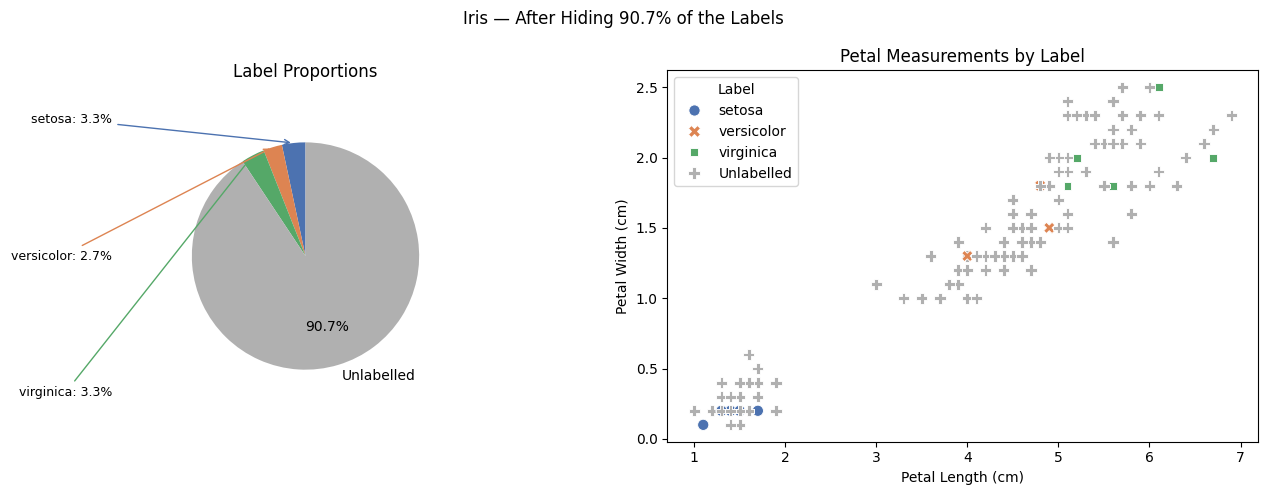

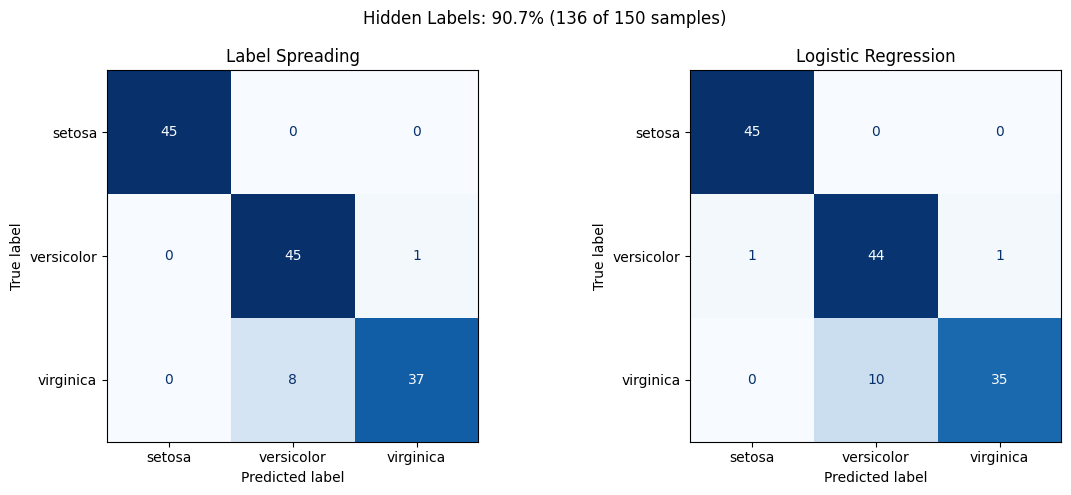

In [13]:
plot_iris(
    iris,
    labels=un_labelled_scarce,
    title=f"Iris — After Hiding {scarce.mean():.1%} of the Labels",
)

hidden_scarce = un_labelled_scarce == -1

plot_confusion_matrices(
    true_labels=iris.target,
    hidden=hidden_scarce,
    label_spreading_predictions=ls_pred_scarce,
    logistic_regression_predictions=lr_pred_scarce,
    class_names=iris.target_names,
)

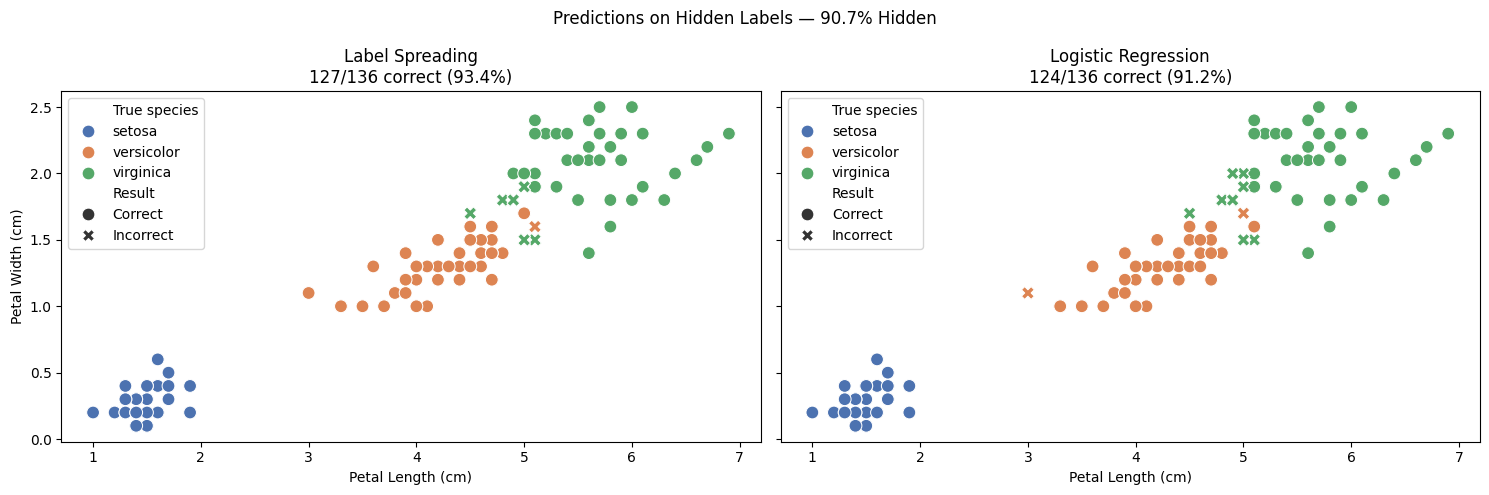

In [14]:
plot_prediction_results(
    iris=iris,
    hidden=scarce,
    label_spreading_predictions=ls_pred_scarce,
    logistic_regression_predictions=lr_pred_scarce,
)

<h1>What did we learn?</h1>

- **`-1` means "unlabelled".** This is the convention used by scikit-learn's
  `LabelSpreading` model for samples whose labels are unknown.
- **Evaluate against the true labels.** We preserved `iris.target` and used it
  to evaluate recovery of hidden labels. Comparing predictions with themselves
  would give a meaningless 100% score.
- **With a 70% hiding probability:** the saved seeded run retained 39 labels
  and hid 111 (74.0%). Label Spreading recovered 92.8% of the hidden labels,
  while Logistic Regression scored 95.5%.
- **With a 90% hiding probability:** the saved seeded run retained 14 labels
  and hid 136 (90.7%). Label Spreading scored 93.4%, compared with 91.2%
  for Logistic Regression.
- **These are hidden-label recovery scores, not independent test-set scores.**
  Label Spreading used all flowers' measurements during fitting.
- **Scarce labels can make semi-supervised learning useful, but do not guarantee
  better performance.** These results describe one seeded comparison; other
  splits and model settings can give different outcomes.